# Stichprobenplanung für den NER-Goldstandard (Label `FIGUR`)


## Konfiguration

In [ ]:
from pathlib import Path
import csv, json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spacy
from spacy.tokens import DocBin

# ── Pfade (bei Bedarf anpassen) ─────────────────────────────
DEV_PATH   = Path("corpus/dev.spacy")      # Gold-Dev-Daten (DocBin)
MODEL_PATH = Path("output/model-best")     # trainiertes Modell

# ── Bootstrap-Parameter ─────────────────────────────────────
SIZES = [50, 100, 150, 200, 290]   # untersuchte Stichprobengrößen (Sätze)
REPS  = 1000                       # Bootstrap-Wiederholungen je Größe
SEED  = 42                         # Reproduzierbarkeit

# ── Zielpräzision ───────────────────────────────────────────
ZIEL_HALBBREITE_GESAMT    = 5.0    # ±F1-Punkte für den Gesamtscore
ZIEL_HALBBREITE_SAMMLUNG  = 8.0    # ±F1-Punkte je Sammlung
N_SAMMLUNGEN              = 4      # Grimm, Andersen, japanisch, arabisch
TRANCHE                   = 75     # Sätze je Annotations-Tranche (sequentiell)

OUT_DIR = Path("ergebnisse")
OUT_DIR.mkdir(exist_ok=True)

print(f"spaCy {spacy.__version__} | numpy {np.__version__} | "
      f"Ausgaben nach: {OUT_DIR.resolve()}")

/home/timc/Workspace/fairytale-personality-profiling/venv_fairytale-profiling/lib/python3.13/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12090). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


spaCy 3.8.14 | numpy 2.4.4 | Ausgaben nach: /home/timc/Workspace/fairytale-personality-profiling/ergebnisse


## Schritt 1 — Modell und Dev-Set laden


In [2]:
nlp = spacy.load(MODEL_PATH)
gold_docs = list(DocBin().from_disk(DEV_PATH).get_docs(nlp.vocab))

n_ents = sum(len(d.ents) for d in gold_docs)
labels = {e.label_ for d in gold_docs for e in d.ents}
print(f"Dev-Dokumente : {len(gold_docs)}")
print(f"Gold-Entitäten: {n_ents}  (≈ {n_ents/len(gold_docs):.2f} je Satz)")
print(f"Labels        : {labels}")
assert gold_docs, "Keine Dokumente geladen — DEV_PATH prüfen."

Dev-Dokumente : 290
Gold-Entitäten: 372  (≈ 1.28 je Satz)
Labels        : {'FIGUR'}


## Schritt 2 — Ein Modelldurchlauf: TP/FP/FN pro Satz


In [ ]:
def entity_set(doc):
    return {(e.start_char, e.end_char, e.label_) for e in doc.ents}

def per_doc_counts(nlp, gold_docs):
    tp = np.zeros(len(gold_docs), dtype=np.int64)
    fp = np.zeros_like(tp)
    fn = np.zeros_like(tp)
    texts = [d.text for d in gold_docs]
    for i, pred in enumerate(nlp.pipe(texts, batch_size=64)):
        g, p = entity_set(gold_docs[i]), entity_set(pred)
        tp[i] = len(g & p)
        fp[i] = len(p - g)
        fn[i] = len(g - p)
    return tp, fp, fn

In [4]:
tp_arr, fp_arr, fn_arr = per_doc_counts(nlp, gold_docs)

TP, FP, FN = int(tp_arr.sum()), int(fp_arr.sum()), int(fn_arr.sum())
punktschaetzer = 2 * TP / (2 * TP + FP + FN)
print(f"TP={TP}  FP={FP}  FN={FN}")
print(f"ENTS_F auf vollem Dev-Set (Punktschätzer): {punktschaetzer:.4f}")
print("→ Sollte ≈ 0.71 sein (Wert aus dem Trainingslog).")

TP=346  FP=47  FN=26
ENTS_F auf vollem Dev-Set (Punktschätzer): 0.9046
→ Sollte ≈ 0.71 sein (Wert aus dem Trainingslog).


In [5]:
counts_path = OUT_DIR / "dev_counts.csv"
with open(counts_path, "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["satz_id", "tp", "fp", "fn"])
    for i in range(len(tp_arr)):
        w.writerow([i, int(tp_arr[i]), int(fp_arr[i]), int(fn_arr[i])])
print(f"Gespeichert: {counts_path}")

Gespeichert: ergebnisse/dev_counts.csv


## Schritt 3 — Bootstrap: F1-Streuung als Funktion der Stichprobengröße


In [ ]:
def micro_f1(tp, fp, fn):
    denom = 2 * tp + fp + fn
    return np.where(denom > 0, 2 * tp / denom, 0.0)

rng = np.random.default_rng(SEED)
sizes_eff = sorted({min(n, len(tp_arr)) for n in SIZES})

rows, dists = [], {}
for n in sizes_eff:
    idx = rng.integers(0, len(tp_arr), size=(REPS, n))   # mit Zurücklegen
    f1 = micro_f1(tp_arr[idx].sum(1), fp_arr[idx].sum(1), fn_arr[idx].sum(1))
    lo, hi = np.percentile(f1, [2.5, 97.5])
    rows.append({
        "n_saetze": n,
        "entitaeten_mittel": float((tp_arr[idx] + fn_arr[idx]).sum(1).mean()),
        "f1_mittel": float(f1.mean()),
        "ci_lo": float(lo),
        "ci_hi": float(hi),
        "ci_halbbreite": float((hi - lo) / 2),
    })
    dists[n] = f1

df = pd.DataFrame(rows)
df_anzeige = df.copy()
df_anzeige["± F1-Punkte"] = (100 * df_anzeige["ci_halbbreite"]).round(1)
df_anzeige.round(3)

,n_saetze,entitaeten_mittel,f1_mittel,ci_lo,ci_hi,ci_halbbreite,± F1-Punkte
0,50,64.316,0.902,0.835,0.954,0.060,6.0
1,100,128.278,0.905,0.861,0.943,0.041,4.1
2,150,191.441,0.904,0.870,0.936,0.033,3.3
3,200,256.067,0.904,0.870,0.931,0.031,3.1
4,290,372.592,0.905,0.877,0.928,0.026,2.6


## Schritt 4 — Visualisierung der n→CI-Kurve


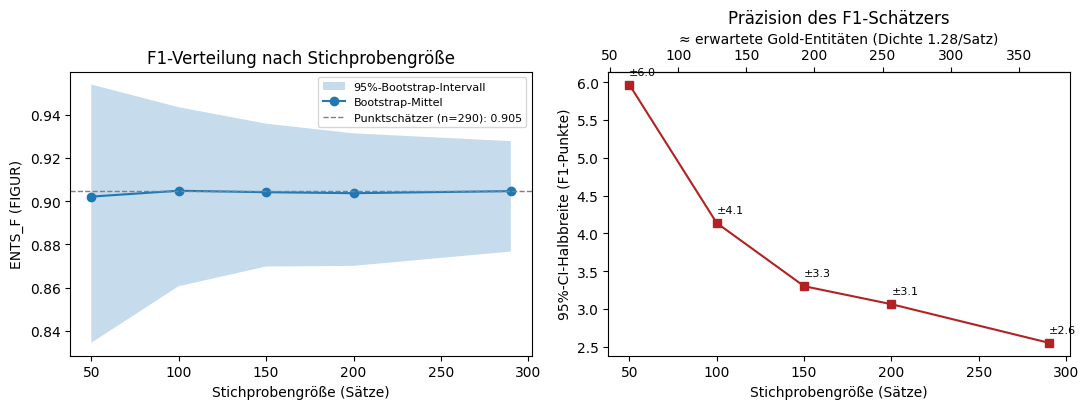

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

ns = df["n_saetze"]
ax1.fill_between(ns, df["ci_lo"], df["ci_hi"], alpha=0.25,
                 label="95%-Bootstrap-Intervall")
ax1.plot(ns, df["f1_mittel"], "o-", label="Bootstrap-Mittel")
ax1.axhline(punktschaetzer, ls="--", c="grey", lw=1,
            label=f"Punktschätzer (n={len(tp_arr)}): {punktschaetzer:.3f}")
ax1.set_xlabel("Stichprobengröße (Sätze)")
ax1.set_ylabel("ENTS_F (FIGUR)")
ax1.set_title("F1-Verteilung nach Stichprobengröße")
ax1.legend(fontsize=8)

ax2.plot(ns, 100 * df["ci_halbbreite"], "s-", color="firebrick")
for _, r in df.iterrows():
    ax2.annotate(f'±{100*r["ci_halbbreite"]:.1f}',
                 (r["n_saetze"], 100 * r["ci_halbbreite"]),
                 textcoords="offset points", xytext=(0, 7), fontsize=8)
ax2.set_xlabel("Stichprobengröße (Sätze)")
ax2.set_ylabel("95%-CI-Halbbreite (F1-Punkte)")
ax2.set_title("Präzision des F1-Schätzers")

# Sekundärachse: Sätze → erwartete Gold-Entitäten (über mittlere Dichte)
dichte = float((tp_arr + fn_arr).mean())
sek = ax2.secondary_xaxis(
    "top", functions=(lambda s: s * dichte, lambda e: e / dichte))
sek.set_xlabel(f"≈ erwartete Gold-Entitäten (Dichte {dichte:.2f}/Satz)")

fig.tight_layout()
fig.savefig(OUT_DIR / "bootstrap_ci_kurve.png", dpi=200)
plt.show()

## Schritt 5 — Ergebnisse sichern


In [26]:
df.to_csv(OUT_DIR / "bootstrap_ci_kurve.csv", index=False)
np.savez(OUT_DIR / "bootstrap_verteilungen.npz",
         **{f"n{n}": d for n, d in dists.items()})

meta = dict(
    dev_path=str(DEV_PATH), model_path=str(MODEL_PATH),
    n_dokumente=len(tp_arr), gold_entitaeten=int((tp_arr + fn_arr).sum()),
    punktschaetzer_ents_f=round(punktschaetzer, 4),
    sizes=sizes_eff, reps=REPS, seed=SEED,
    spacy_version=spacy.__version__, numpy_version=np.__version__,
)
(OUT_DIR / "bootstrap_meta.json").write_text(
    json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")

print("Gespeichert:",
      *[p.name for p in OUT_DIR.glob("bootstrap_*")], sep="\n  - ")

Gespeichert:
  - bootstrap_ci_kurve.png
  - bootstrap_ci_kurve.csv
  - bootstrap_verteilungen.npz
  - bootstrap_meta.json


## Schritt 6 — Erforderliche Stichprobengröße ableiten (+ Methodenabsatz)


In [9]:
ns_arr = df["n_saetze"].to_numpy(dtype=float)
hb_arr = 100 * df["ci_halbbreite"].to_numpy(dtype=float)   # in F1-Punkten
dichte = float((tp_arr + fn_arr).mean())

# ── Fit: HB ≈ c / sqrt(n)  (Kleinste Quadrate durch den Ursprung) ──
x = 1.0 / np.sqrt(ns_arr)
c = float((x @ hb_arr) / (x @ x))
fit = c / np.sqrt(ns_arr)
mae = float(np.mean(np.abs(fit - hb_arr)))

fit_check = pd.DataFrame({"n_saetze": ns_arr.astype(int),
                          "HB empirisch": hb_arr.round(2),
                          "HB Fit c/√n": fit.round(2),
                          "Abweichung": (hb_arr - fit).round(2)})
print(f"Angepasst: HB ≈ {c:.1f}/√n Punkte | mittl. |Abweichung| = {mae:.2f} Pkt.")
print(fit_check.to_string(index=False))

# ── Inversion: erforderliches n je Zielpräzision ──
def n_fuer(ziel_punkte):
    return int(np.ceil((c / ziel_punkte) ** 2))

ziele = sorted({4.0, 5.0, 6.0, 8.0, 10.0,
                float(ZIEL_HALBBREITE_GESAMT), float(ZIEL_HALBBREITE_SAMMLUNG)})
bedarf = pd.DataFrame([{
    "Ziel ±Punkte": z,
    "erforderl. Sätze": n_fuer(z),
    "≈ Entitäten": int(round(n_fuer(z) * dichte)),
    "Tranchen à %d" % TRANCHE: int(np.ceil(n_fuer(z) / TRANCHE)),
    "Extrapolation": "ja" if n_fuer(z) > len(tp_arr) else "",
} for z in ziele])
print("\nBedarf nach Zielpräzision (Gesamtscore bzw. je Einheit):")
print(bedarf.to_string(index=False))
bedarf.to_csv(OUT_DIR / "stichprobenbedarf.csv", index=False)

n_gesamt  = n_fuer(ZIEL_HALBBREITE_GESAMT)
n_je_samm = n_fuer(ZIEL_HALBBREITE_SAMMLUNG)
n_samm_ges = n_je_samm * N_SAMMLUNGEN
n_massgeblich = max(n_gesamt, n_samm_ges)
print(f"\nKonfigurierte Ziele:")
print(f"  Gesamtscore ±{ZIEL_HALBBREITE_GESAMT:.0f} Pkt.  → ≈ {n_gesamt} Sätze")
print(f"  je Sammlung ±{ZIEL_HALBBREITE_SAMMLUNG:.0f} Pkt. → ≈ {n_je_samm} Sätze/Sammlung "
      f"→ ≈ {n_samm_ges} gesamt ({N_SAMMLUNGEN} Sammlungen)")
print(f"  bindend: ≈ {n_massgeblich} Sätze "
      f"≈ {int(np.ceil(n_massgeblich / TRANCHE))} Tranchen à {TRANCHE}")

# ── Grenznutzen: was bringt eine weitere Tranche? ──
marken = [TRANCHE * k for k in range(1, int(np.ceil(n_massgeblich / TRANCHE)) + 2)]
print("\nGrenznutzen (Modellkurve): Halbbreite nach k Tranchen")
for m in marken:
    print(f"  {m:>4} Sätze: ±{c/np.sqrt(m):.1f} Pkt.")

extra = (f" Bedarfe oberhalb von {len(tp_arr)} Sätzen extrapolieren die "
         f"angepasste Kurve.") if n_massgeblich > len(tp_arr) else ""

absatz = f"""Der Umfang des Goldstandards wurde nicht vorab festgesetzt, sondern aus einer a priori definierten Zielpräzision abgeleitet. Als Kriterium wurde eine 95%-Konfidenzintervall-Halbbreite von ±{ZIEL_HALBBREITE_GESAMT:.0f} F1-Punkten für den Gesamtscore und ±{ZIEL_HALBBREITE_SAMMLUNG:.0f} Punkten je Sammlung festgelegt; es folgt aus den geplanten Vergleichsaussagen und ist nach unten durch die Annotationsunsicherheit begrenzt (Inter-Annotator-Agreement auf einer Teilmenge), unterhalb derer engere Intervalle Scheinpräzision bedeuteten. Zur Prognose des dafür erforderlichen Umfangs wurde auf dem Development-Set ({len(tp_arr)} Sätze, {int((tp_arr + fn_arr).sum())} FIGUR-Entitäten; ENTS_F = {punktschaetzer:.3f}) per Bootstrap ({REPS} Ziehungen mit Zurücklegen, Seed {SEED}) die Halbbreite der Mikro-F1 für Teilstichproben gemessen; sie folgt dem erwarteten 1/√n-Verlauf (Anpassung: HB ≈ {c:.1f}/√n Punkte, mittlere Abweichung {mae:.2f} Punkte). Inversion der Kurve ergibt einen Bedarf von rund {n_gesamt} Sätzen für den Gesamtscore und rund {n_je_samm} Sätzen je Sammlung (≈ {n_samm_ges} gesamt bei {N_SAMMLUNGEN} Sammlungen; Entitätendichte {dichte:.2f} Vorkommen je Satz).{extra} Da die statistische Information vom Entitätsvorkommen getragen wird, gezogen aber auf Satzebene wird — der realen Auswahl- und Annotationseinheit; Sätze ohne Figurennennung tragen zur Präzisionsmessung bei, und die schwankende Entitätendichte ist Teil der Designvarianz —, lässt sich der Bedarf bei abweichender Dichte des Goldstandards über die Entitätenzahl umrechnen. Die Prognose ist als Untergrenze zu lesen: Das Development-Set ist in-domain (satzweiser Zufallssplit, dieselben Erzählungen wie das Training) und enthält keine Cluster-Korrelation. Verbindlich ermittelt wird der Umfang deshalb sequentiell am Goldstandard selbst: Annotation in Tranchen à {TRANCHE} Sätzen, nach jeder Tranche Berechnung der Konfidenzintervalle per Cluster-Bootstrap über Erzählungen, Abbruch bei Erreichen der Zielpräzision beziehungsweise des IAA-Niveaus."""

print("\n" + absatz)
(OUT_DIR / "methodenabsatz.txt").write_text(absatz, encoding="utf-8")
print(f"\nGespeichert: {OUT_DIR / 'methodenabsatz.txt'}, "
      f"{OUT_DIR / 'stichprobenbedarf.csv'}")

Angepasst: HB ≈ 42.0/√n Punkte | mittl. |Abweichung| = 0.08 Pkt.
 n_saetze  HB empirisch  HB Fit c/√n  Abweichung
       50          5.97         5.94        0.03
      100          4.14         4.20       -0.06
      150          3.30         3.43       -0.13
      200          3.06         2.97        0.09
      290          2.55         2.46        0.09

Bedarf nach Zielpräzision (Gesamtscore bzw. je Einheit):
 Ziel ±Punkte  erforderl. Sätze  ≈ Entitäten  Tranchen à 75 Extrapolation
          4.0               111          142              2              
          5.0                71           91              1              
          6.0                49           63              1              
          8.0                28           36              1              
         10.0                18           23              1              

Konfigurierte Ziele:
  Gesamtscore ±5 Pkt.  → ≈ 71 Sätze
  je Sammlung ±8 Pkt. → ≈ 28 Sätze/Sammlung → ≈ 112 gesamt (4 Sammlungen)
  binde